# Phase 2: component meanline models

The cycle model (Phase 1) needed a pressure ratio and an efficiency *assumed* for each component. A **meanline model** computes them from the component's **geometry** and **operating point** (shaft speed, mass flow), using velocity triangles and empirical loss correlations. Scanning mass flow at fixed speed gives a *speed line*; several speed lines make a *map*, which is what off-design engine matching needs (Phase 3).

* **Compressor:** TurboML's own meanline model (`turboml/physics/compressor.py`), Oh et al. (1997) losses + 1-D vaneless diffuser. Checked against the KJ-66 **measured** data.
* **Turbine:** TurboFlow's axial-turbine solver (`turboml/physics/turbine.py`). Checked against NASA's Kofskey (1972) **measured** data.

In [1]:
import os, warnings
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt, yaml
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd(); os.chdir(ROOT)
warnings.filterwarnings('ignore')
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']
INK, MUTED, GRID = '#1f1f1e', '#6b6a63', '#e4e3dd'
plt.rcParams.update({'axes.edgecolor': MUTED, 'axes.labelcolor': INK, 'xtick.color': MUTED,
    'ytick.color': MUTED, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 2, 'font.size': 10})
P2 = ROOT / 'validation' / 'phase2'
exp = pd.read_csv('validation/cases/kj66_compressor_exp_murray2009.csv', comment='#')
S = yaml.safe_load((P2 / 'kj66_summary.yaml').read_text())
SPEEDS = [70000, 80000, 90000, 100000, 110000]

## 1. KJ-66 compressor: blind prediction vs measurement
**Blind** means we used only the published geometry (Xiang 2016, Ling 2007) plus documented assumptions for what isn't published, with no tuning. Dots are **measured** engine data (Murray 2009, digitized from Xiang's figure). Lines are our model.

,PR error mean [%],PR error max |.| [%],eta error mean [pts],eta error max |.| [pts]
TurboML (blind),20.91,33.81,13.34,15.58
RadComp (blind),11.55,17.98,3.18,5.81


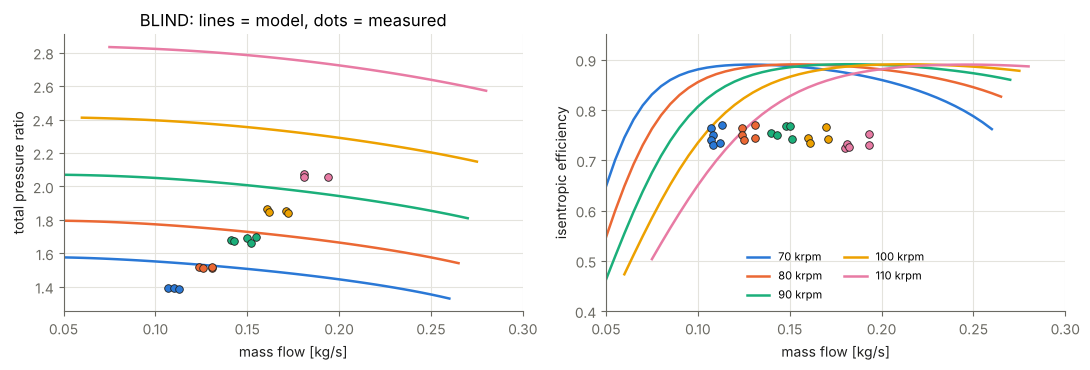

In [2]:
uq = pd.read_csv(P2 / 'kj66_speedlines_slip_uq.csv'); cal = pd.read_csv(P2 / 'kj66_speedlines_calibrated.csv')
def plot_lines(ax, d, col, ls='-', label_lines=True):
    for i, N in enumerate(SPEEDS):
        g = d[(d.speed_rpm == N) & d.converged & ~d.surge_side]
        ax.plot(g.mass_flow_kg_s, g[col], ls, color=SERIES[i], lw=1.8, label=f'{N//1000} krpm' if label_lines else None)
def plot_exp(ax, q):
    for i, N in enumerate(SPEEDS):
        e = exp[(exp.speed_rpm == N) & (exp.quantity == q)]
        ax.scatter(e.mass_flow_kg_s, e.value, s=30, color=SERIES[i], edgecolor=INK, linewidth=0.6, zorder=4)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col, q, yl in [(axes[0], 'pr_tt', 'pressure_ratio', 'total pressure ratio'), (axes[1], 'eta_tt', 'efficiency_ad', 'isentropic efficiency')]:
    plot_lines(ax, uq[uq.delta_sigma == 0.0], col); plot_exp(ax, q)
    ax.set(xlabel='mass flow [kg/s]', ylabel=yl, xlim=(0.05, 0.3))
axes[0].set_title('BLIND: lines = model, dots = measured'); axes[1].set_ylim(0.4, 0.95)
axes[1].legend(frameon=False, fontsize=8, ncol=2, loc='lower center'); fig.tight_layout()
def flat(d):
    return {'PR error mean [%]': d['PR_rel_err']['mean'], 'PR error max |.| [%]': d['PR_rel_err']['max_abs'],
            'eta error mean [pts]': d['eta_abs_err_pts']['mean'], 'eta error max |.| [pts]': d['eta_abs_err_pts']['max_abs']}
pd.DataFrame({'TurboML (blind)': flat(S['blind_turboml']), 'RadComp (blind)': flat(S['blind_radcomp'])}).T

The blind model **over-predicts** pressure ratio by about 21 % and efficiency by about 13 points. RadComp, a completely independent meanline code with different loss correlations, also over-predicts (about 12 % in PR). Two independent loss sets agreeing with each other but not with the engine points at the **inputs** rather than the loss models. The unknowns are:
* the real blade exit angle (backsweep) and slip: these set the work input;
* the real **wedge-vaned diffuser + 90° turn** (not published; modelled here as a vaneless diffuser), which costs pressure the model doesn't see.

## 2. Slip factor is uncertain, and it matters
The slip factor σ sets how much of the blade speed becomes swirl, and therefore the work. The Wiesner correlation is known to be within ±0.05 for only about half of the impellers tested (Harrison 2020, via the project brief). The band shows the nominal model's PR for Δσ = ±0.05 (dark) and ±0.10 (light).

-0.10    10.88
-0.05    15.87
 0.00    20.91
 0.05    26.01
 0.10    31.22
Name: mean PR error vs measured [%], dtype: float64

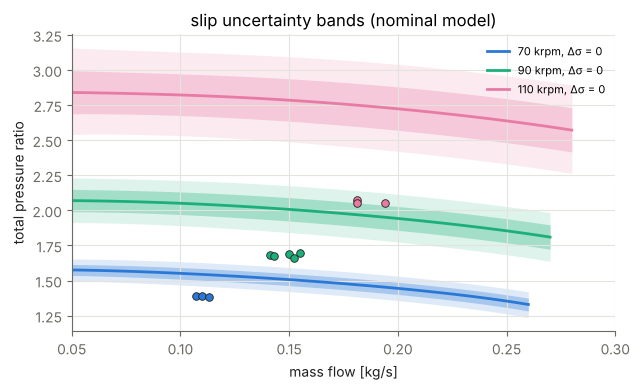

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for N in [70000, 90000, 110000]:
    j = SPEEDS.index(N)
    lines = {ds: uq[(uq.speed_rpm == N) & (uq.delta_sigma == ds) & uq.converged].set_index('mass_flow_kg_s').pr_tt for ds in [-0.1, -0.05, 0.0, 0.05, 0.1]}
    m = sorted(set.intersection(*[set(v.index) for v in lines.values()]))
    ax.fill_between(m, lines[-0.1][m], lines[0.1][m], color=SERIES[j], alpha=0.15, lw=0)
    ax.fill_between(m, lines[-0.05][m], lines[0.05][m], color=SERIES[j], alpha=0.30, lw=0)
    ax.plot(m, lines[0.0][m], color=SERIES[j], label=f'{N//1000} krpm, Δσ = 0')
    e = exp[(exp.speed_rpm == N) & (exp.quantity == 'pressure_ratio')]
    ax.scatter(e.mass_flow_kg_s, e.value, s=30, color=SERIES[j], edgecolor=INK, linewidth=0.6, zorder=4)
ax.set(xlabel='mass flow [kg/s]', ylabel='total pressure ratio', xlim=(0.05, 0.3), title='slip uncertainty bands (nominal model)')
ax.legend(frameon=False, fontsize=8); fig.tight_layout()
pd.Series(S['slip_uq_PR_rel_err_mean_by_delta_sigma'], name='mean PR error vs measured [%]')

A change of 0.05 in σ moves PR by about 5 %, which is as large as the whole remaining error after calibration. Slip is therefore an uncertain input to propagate later (UQ), not a constant.

## 3. Calibration on ONE speed, validation on the others
We fit two physically motivated *effective* parameters to the **90 krpm** measurements only:
* Δσ: lowers the work input (absorbing unknown backsweep and slip);
* diffuser friction Cf: adds the pressure loss of the real wedge diffuser and bend.

Then we check the **other four speeds**, which the fit never saw.

fitted: delta_sigma = -0.1041 (slip factor 0.7031), diffuser Cf = 0.0937


,PR error mean [%],PR error max |.| [%],eta error mean [pts],eta error max |.| [pts]
calibration speed (90k),-0.00,1.17,-0.03,1.58
validation speeds (70/80/100/110k),1.14,4.58,0.92,3.13


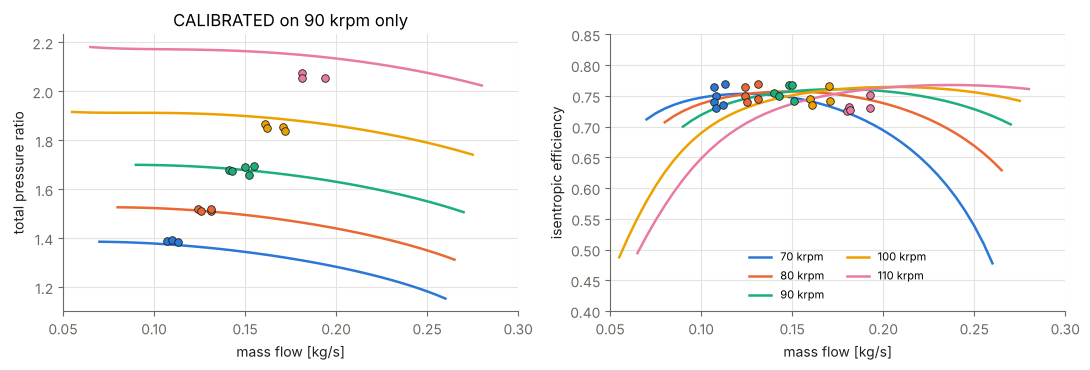

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col, q, yl in [(axes[0], 'pr_tt', 'pressure_ratio', 'total pressure ratio'), (axes[1], 'eta_tt', 'efficiency_ad', 'isentropic efficiency')]:
    plot_lines(ax, cal, col); plot_exp(ax, q)
    ax.set(xlabel='mass flow [kg/s]', ylabel=yl, xlim=(0.05, 0.3))
axes[0].set_title('CALIBRATED on 90 krpm only'); axes[1].set_ylim(0.4, 0.85)
axes[1].legend(frameon=False, fontsize=8, ncol=2, loc='lower center'); fig.tight_layout()
c = S['calibration']
print(f"fitted: delta_sigma = {c['delta_sigma']} (slip factor {c['slip_factor']}), diffuser Cf = {c['diffuser_cf']}")
pd.DataFrame({'calibration speed (90k)': flat(c['calibration_speed_errors']), 'validation speeds (70/80/100/110k)': flat(c['validation_speed_errors'])}).T

On speeds the fit never saw, PR is within **±4.6 %** (mean +1.1 %) and efficiency within **±3.1 points** (mean +0.9). The measured trends are reproduced: PR rises steeply with speed, and peak efficiency stays almost flat (~0.75–0.77), as in the engine data. The CFD's efficiency drop from 0.73 to 0.55 is not reproduced, and the measurements don't show it either.

**Caveats:** the fitted Cf ≈ 0.09 is far above a plain vaneless-diffuser value, and Δσ ≈ −0.10 is large. Both are *effective* numbers that lump unknown geometry. The calibration rests on one engine (digitized data), so transferring it to other designs is a modelling decision; see the report.

## 4. The compressor map: surge and choke
* **Choke** (right end of each line): the impeller throat reaches Mach 1, so the flow can't increase.
* **Surge** (left end): meanline models can't predict surge reliably. We flag the first of (a) an interior pressure-ratio peak or (b) the vaneless-diffuser stall angle of Senoo & Kinoshita (1977). The measured data contains no surge points, so this criterion is **not validated**.

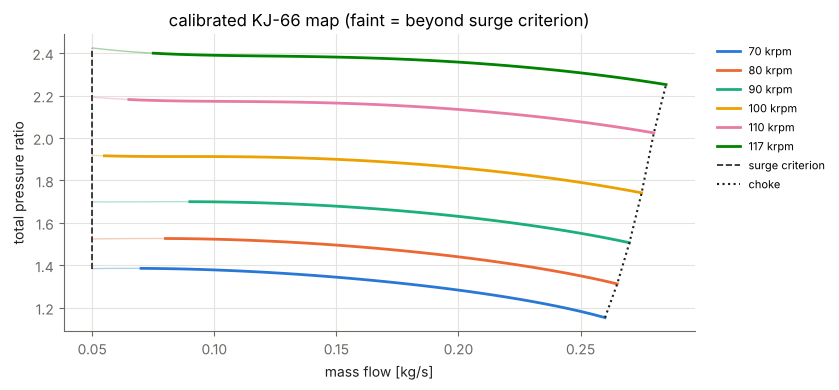

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 4))
SP6 = SPEEDS + [117000]
surge, choke = [], []
for i, N in enumerate(SP6):
    g = cal[(cal.speed_rpm == N) & cal.converged]
    stable = g[~g.surge_side]
    ax.plot(g.mass_flow_kg_s, g.pr_tt, color=SERIES[i], lw=1, alpha=0.35)
    ax.plot(stable.mass_flow_kg_s, stable.pr_tt, color=SERIES[i], label=f'{N//1000} krpm')
    s = g[g.surge_criterion != '']
    if len(s): surge.append((s.mass_flow_kg_s.iloc[0], s.pr_tt.iloc[0]))
    choke.append((g.mass_flow_kg_s.iloc[-1], g.pr_tt.iloc[-1]))
ax.plot(*zip(*surge), '--', color=INK, lw=1.2, label='surge criterion')
ax.plot(*zip(*choke), ':', color=INK, lw=1.5, label='choke')
ax.set(xlabel='mass flow [kg/s]', ylabel='total pressure ratio', title='calibrated KJ-66 map (faint = beyond surge criterion)')
ax.legend(frameon=False, fontsize=8, loc='upper left', bbox_to_anchor=(1.02, 1)); fig.tight_layout()

## 5. Axial turbine: Kofskey (1972) NASA cold-air turbine
No tuning: published geometry, TurboFlow's Benner loss set. Lines = model, dots = measured.

,unit,mean,mean |error|,max |error|,n points
efficiency_ts,pts,-1.18,1.42,2.83,106
exit_flow_angle,deg,-0.1,1.78,6.63,50
mass_flow,%,1.13,1.13,2.69,46
torque,%,-0.52,1.48,5.19,60


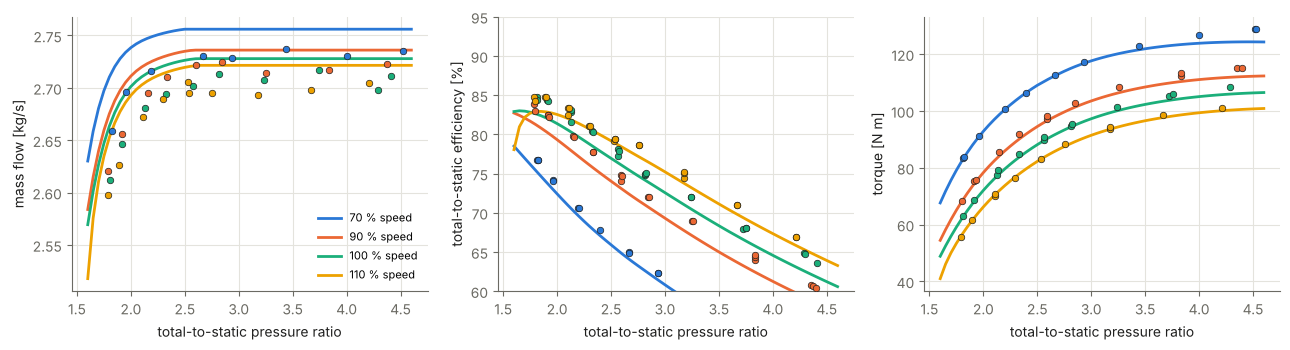

In [6]:
km = pd.read_csv(P2 / 'kofskey_map.csv'); kd = pd.read_csv('validation/cases/kofskey1972_turbine_measured.csv', comment='#')
KS = [70, 90, 100, 110]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col, q, scale, yl in [(axes[0], 'mass_flow_kg_s', 'mass_flow', 1, 'mass flow [kg/s]'),
                              (axes[1], 'eta_ts', 'efficiency_ts', 100, 'total-to-static efficiency [%]'),
                              (axes[2], 'torque_N_m', 'torque', 1, 'torque [N m]')]:
    for i, sp in enumerate(KS):
        g = km[(km.speed_pct_design == sp) & km.converged]
        ax.plot(g.pr_ts, scale * g[col], color=SERIES[i], label=f'{sp} % speed')
        e = kd[(kd.speed_pct_design == sp) & (kd.quantity == q)]
        ax.scatter(e.pressure_ratio_ts, e.value, s=22, color=SERIES[i], edgecolor=INK, linewidth=0.5, zorder=4)
    ax.set(xlabel='total-to-static pressure ratio', ylabel=yl)
axes[1].set_ylim(60, 95); axes[0].legend(frameon=False, fontsize=8); fig.tight_layout()
ks = yaml.safe_load((P2 / 'kofskey_summary.yaml').read_text())
rows = {}
for q, e in ks['errors'].items():
    unit = [k for k in e if k.startswith('mean_abs_') and not k.endswith('pct')][0].split('_')[-1]
    rows[q] = {'unit': unit, 'mean': e[f'mean_{unit}'], 'mean |error|': e[f'mean_abs_{unit}'], 'max |error|': e[f'max_abs_{unit}'], 'n points': e['n']}
pd.DataFrame(rows).T

Untuned errors: efficiency about **1.4 points** (mean absolute), mass flow **1.1 %**, torque **1.5 %**. This is the published case the Phase 2 acceptance asks for.

## 6. Running the turbine on air instead of combustion gas
TurboFlow uses CoolProp fluids, and kerosene combustion products aren't one. How big is the error of using air at micro-turbine conditions?

In [7]:
ge = pd.read_csv(P2 / 'turbine_gas_error.csv')
ge[['work_err_air_vs_products_%', 'flowfn_err_air_vs_products_%', 'cp_err_%']].describe().loc[['min', 'max']].round(2)

,work_err_air_vs_products_%,flowfn_err_air_vs_products_%,cp_err_%
min,-0.46,0.28,-4.23
max,-0.17,0.47,-2.39


Air under-predicts turbine work by **0.2–0.5 %** and over-predicts the choked flow function by **0.3–0.5 %**. That's small next to the loss-model uncertainty, so it's acceptable for preliminary design, and documented.

## Summary
* **Compressor:** our own fast model (~0.1 s/point). The port is verified against TurboFlow to 0.01 %. Blind KJ-66 error is large (inputs unknown); a 2-parameter calibration on one speed reproduces the other speeds to ±4.6 % PR / ±3.1 pts efficiency. Slip uncertainty is propagated and shown.
* **Turbine:** TurboFlow reproduces a published NASA turbine to about 1–2 % untuned.
* **Open:** surge criterion unvalidated (no surge data); calibration transfer to other designs; turbine speed (3 s/point) for Phase 3. See `docs/PHASE2_REPORT.md`.